In [ ]:
!pip install kmodes

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, f_oneway
from kmodes.kmodes import KModes

In [ ]:
df = pd.read_csv(f"https://data.lacity.org/api/views/2nrs-mtv8/rows.csv")

In [ ]:
df[["Crm Cd 1", "Crm Cd 2", "Crm Cd 3", "Crm Cd 4"]] = df[["Crm Cd 1", "Crm Cd 2", "Crm Cd 3", "Crm Cd 4"]].fillna(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004894 entries, 0 to 1004893
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1004894 non-null  int64  
 1   Date Rptd       1004894 non-null  object 
 2   DATE OCC        1004894 non-null  object 
 3   TIME OCC        1004894 non-null  int64  
 4   AREA            1004894 non-null  int64  
 5   AREA NAME       1004894 non-null  object 
 6   Rpt Dist No     1004894 non-null  int64  
 7   Part 1-2        1004894 non-null  int64  
 8   Crm Cd          1004894 non-null  int64  
 9   Crm Cd Desc     1004894 non-null  object 
 10  Mocodes         853296 non-null   object 
 11  Vict Age        1004894 non-null  int64  
 12  Vict Sex        860263 non-null   object 
 13  Vict Descent    860251 non-null   object 
 14  Premis Cd       1004878 non-null  float64
 15  Premis Desc     1004306 non-null  object 
 16  Weapon Used Cd  327216 non-null   fl

In [ ]:
df.duplicated().any()

np.False_

In [ ]:
columns_nan = ['Mocodes', 'Vict Sex', 'Vict Descent']
for x in columns_nan:
  df.dropna(subset=[f'{x}'], inplace=True)

In [ ]:
df_cluster = df[['AREA', 'Crm Cd', 'Mocodes', 'Vict Sex', 'Vict Descent', 'Crm Cd 1', 'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4']]
df_cluster = df_cluster[:10000]

In [ ]:
import matplotlib.pyplot as plt
from kmodes.kmodes import KModes

def encontrar_k_ideal(dados, k_maximo=10):
    """
    Função para rodar o K-Modes com diferentes valores de K
    e plotar o gráfico de Custo (Método do Cotovelo).
    """
    custos = []
    valores_k = range(1, k_maximo + 1)

    print("Iniciando a busca pelo K ideal...")
    for k in valores_k:
        # Inicialização 'Cao' ou 'Huang' são as mais recomendadas para o K-Modes
        km = KModes(n_clusters=k, init='Cao', n_init=5, random_state=42)
        km.fit(dados)

        # O atributo .cost_ armazena a soma das discrepâncias
        custos.append(km.cost_)
        print(f"K = {k} calculado. Custo: {km.cost_}")

    # Plotando o gráfico do Cotovelo
    plt.figure(figsize=(8, 5))
    plt.plot(valores_k, custos, marker='o', color='b', linestyle='--')
    plt.xlabel('Número de Clusters (K)')
    plt.ylabel('Custo Total (Mismatches)')
    plt.title('Método do Cotovelo para K-Modes')
    plt.xticks(valores_k)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

Iniciando a busca pelo K ideal...
K = 1 calculado. Custo: 38487.0
K = 2 calculado. Custo: 34537.0
K = 3 calculado. Custo: 31954.0
K = 4 calculado. Custo: 30717.0
K = 5 calculado. Custo: 29855.0
K = 6 calculado. Custo: 29389.0
K = 7 calculado. Custo: 28944.0
K = 8 calculado. Custo: 28584.0
K = 9 calculado. Custo: 28180.0
K = 10 calculado. Custo: 27778.0
K = 11 calculado. Custo: 27436.0
K = 12 calculado. Custo: 27190.0
K = 13 calculado. Custo: 26651.0
K = 14 calculado. Custo: 26415.0
K = 15 calculado. Custo: 25754.0
K = 16 calculado. Custo: 25585.0
K = 17 calculado. Custo: 25259.0
K = 18 calculado. Custo: 24966.0
K = 19 calculado. Custo: 24729.0
K = 20 calculado. Custo: 24436.0
K = 21 calculado. Custo: 24364.0
K = 22 calculado. Custo: 24231.0
K = 23 calculado. Custo: 24003.0
K = 24 calculado. Custo: 23895.0
K = 25 calculado. Custo: 23863.0
K = 26 calculado. Custo: 23859.0
K = 27 calculado. Custo: 23848.0
K = 28 calculado. Custo: 23621.0
K = 29 calculado. Custo: 23501.0
K = 30 calculado. 

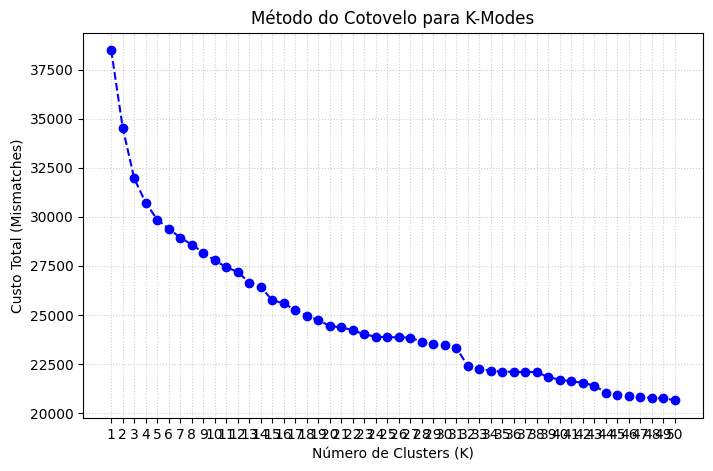

In [ ]:
encontrar_k_ideal(df_cluster, k_maximo=50)

In [ ]:
import matplotlib.pyplot as plt
from kmodes.kmodes import KModes

def encontrar_k_ideal(dados, k_maximo=10):
    """
    Função para rodar o K-Modes com diferentes valores de K
    e plotar o gráfico de Custo (Método do Cotovelo).
    """
    custos = []
    valores_k = range(1, k_maximo + 1)

    print("Iniciando a busca pelo K ideal...")
    for k in valores_k:
        # Inicialização 'Cao' ou 'Huang' são as mais recomendadas para o K-Modes
        km = KModes(n_clusters=k, init='Huang', n_init=5, random_state=42)
        km.fit(dados)

        # O atributo .cost_ armazena a soma das discrepâncias
        custos.append(km.cost_)
        print(f"K = {k} calculado. Custo: {km.cost_}")

    # Plotando o gráfico do Cotovelo
    plt.figure(figsize=(8, 5))
    plt.plot(valores_k, custos, marker='o', color='b', linestyle='--')
    plt.xlabel('Número de Clusters (K)')
    plt.ylabel('Custo Total (Mismatches)')
    plt.title('Método do Cotovelo para K-Modes')
    plt.xticks(valores_k)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

Iniciando a busca pelo K ideal...
K = 1 calculado. Custo: 38487.0
K = 2 calculado. Custo: 34033.0
K = 3 calculado. Custo: 31982.0
K = 4 calculado. Custo: 30229.0
K = 5 calculado. Custo: 29088.0
K = 6 calculado. Custo: 29112.0
K = 7 calculado. Custo: 27507.0
K = 8 calculado. Custo: 27186.0
K = 9 calculado. Custo: 26921.0
K = 10 calculado. Custo: 25946.0
K = 11 calculado. Custo: 26249.0
K = 12 calculado. Custo: 25562.0
K = 13 calculado. Custo: 25374.0
K = 14 calculado. Custo: 25617.0
K = 15 calculado. Custo: 25025.0
K = 16 calculado. Custo: 24356.0
K = 17 calculado. Custo: 24892.0
K = 18 calculado. Custo: 24194.0
K = 19 calculado. Custo: 24020.0
K = 20 calculado. Custo: 23637.0
K = 21 calculado. Custo: 23619.0
K = 22 calculado. Custo: 23576.0
K = 23 calculado. Custo: 23030.0
K = 24 calculado. Custo: 23160.0
K = 25 calculado. Custo: 23381.0
K = 26 calculado. Custo: 23023.0
K = 27 calculado. Custo: 22955.0
K = 28 calculado. Custo: 22796.0
K = 29 calculado. Custo: 22446.0
K = 30 calculado. 

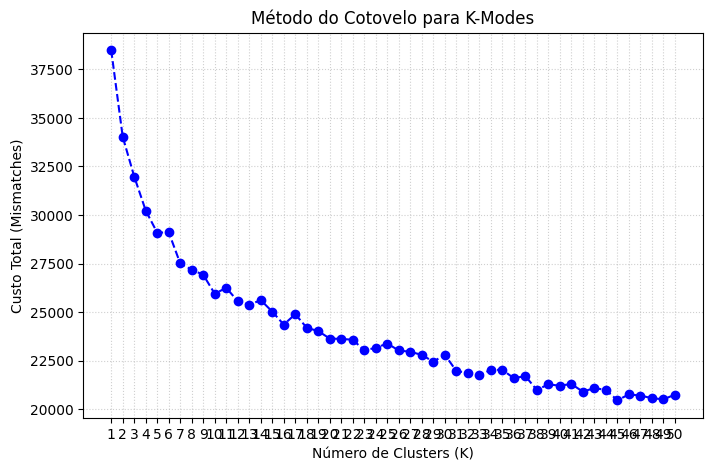

In [ ]:
encontrar_k_ideal(df_cluster, k_maximo=50)

In [ ]:
km = KModes(n_clusters=7, init='Huang', random_state=42, verbose=0)

In [ ]:
df_cluster['cluster_perfil'] = km.fit_predict(df_cluster)

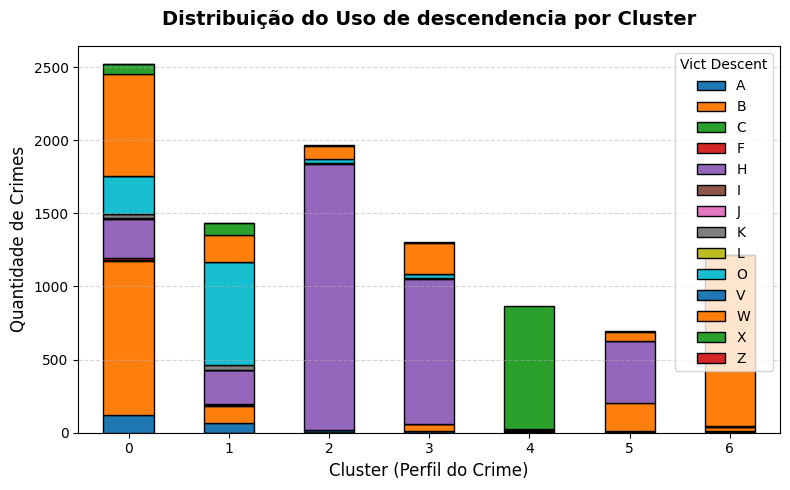

In [ ]:
cruzamento = pd.crosstab(df_cluster['cluster_perfil'], df_cluster['Vict Descent'])


ax = cruzamento.plot(kind='bar', stacked=True, figsize=(8, 5), edgecolor='black')

plt.title('Distribuição do Uso de descendencia por Cluster', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cluster (Perfil do Crime)', fontsize=12)
plt.ylabel('Quantidade de Crimes', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title=cruzamento.columns.name, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

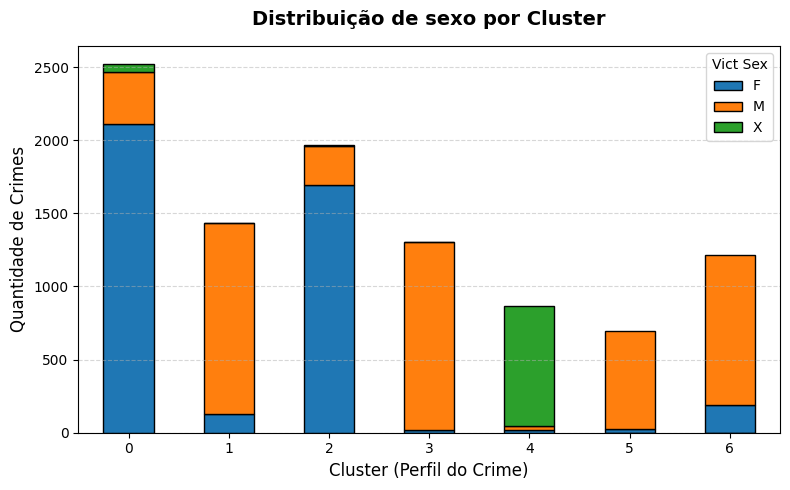

In [ ]:
cruzamento = pd.crosstab(df_cluster['cluster_perfil'], df_cluster['Vict Sex'])

ax = cruzamento.plot(kind='bar', stacked=True, figsize=(8, 5), edgecolor='black')

plt.title('Distribuição de sexo por Cluster', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cluster (Perfil do Crime)', fontsize=12)
plt.ylabel('Quantidade de Crimes', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title=cruzamento.columns.name, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

/tmp/ipykernel_660/4133204056.py:12: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


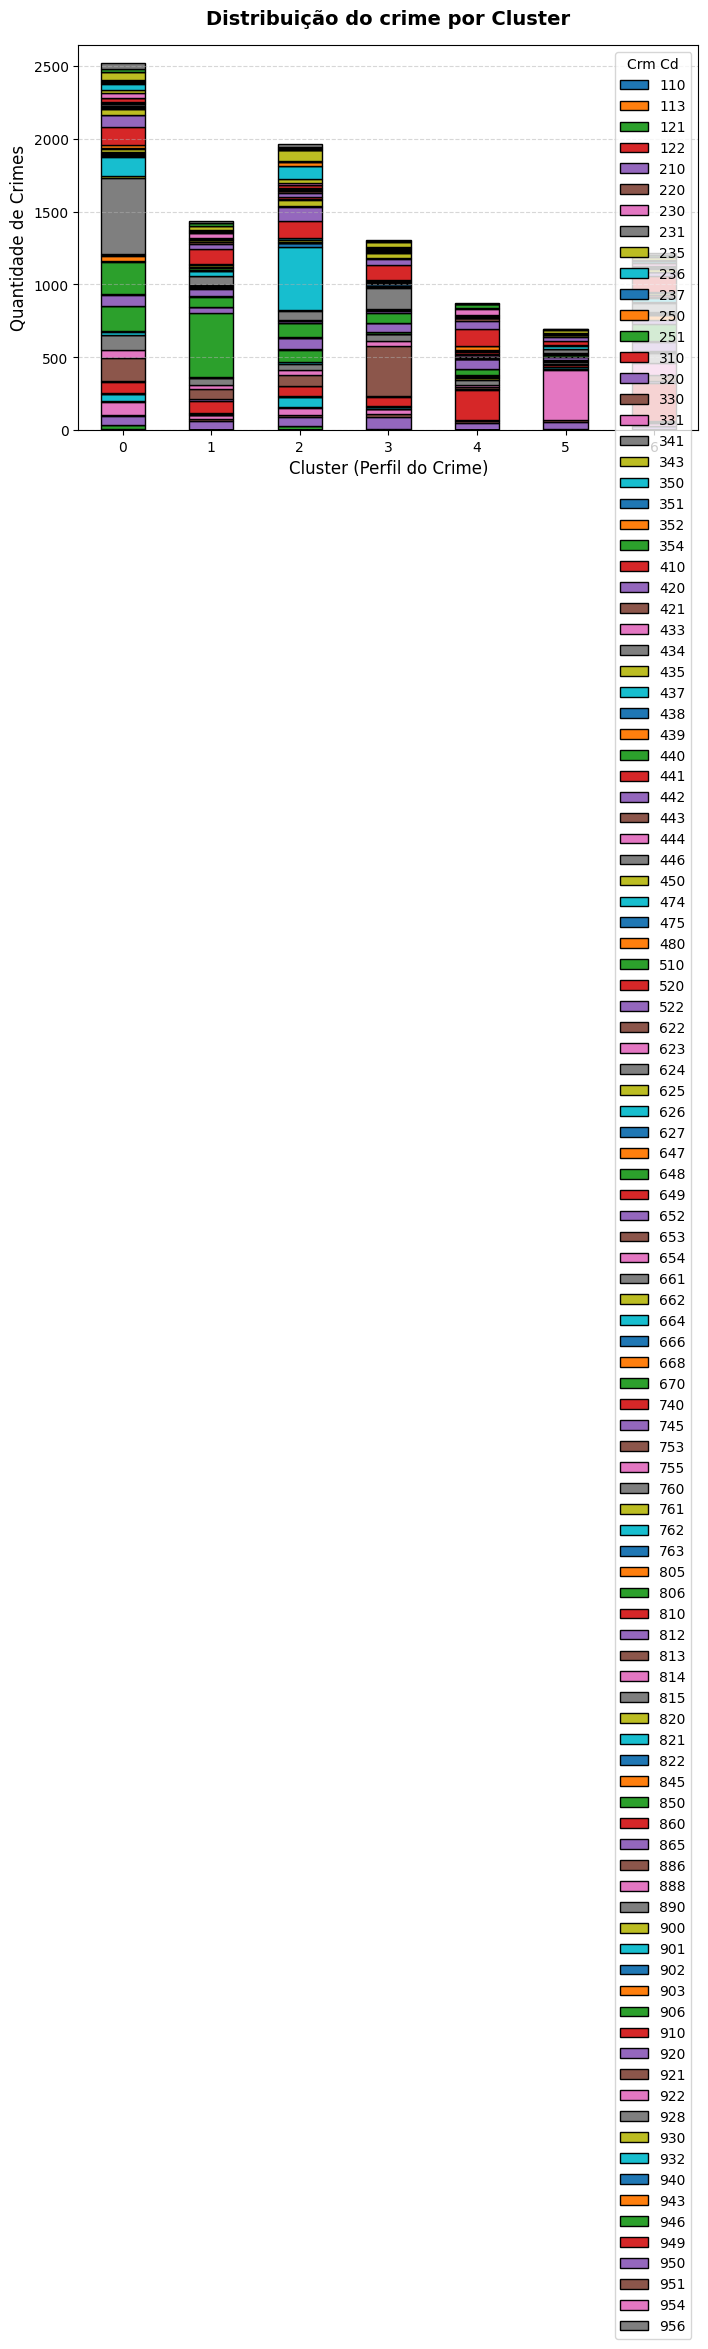

In [ ]:
cruzamento = pd.crosstab(df_cluster['cluster_perfil'], df_cluster['Crm Cd'])

ax = cruzamento.plot(kind='bar', stacked=True, figsize=(8, 5), edgecolor='black')

plt.title('Distribuição do crime por Cluster', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cluster (Perfil do Crime)', fontsize=12)
plt.ylabel('Quantidade de Crimes', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title=cruzamento.columns.name, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
df_cluster_crimes = df[["Crm Cd 1", "Crm Cd 2", "Crm Cd 3", "Crm Cd 4"]]
df_cluster_crimes = df_cluster_crimes[:10000]

km = KModes(n_clusters=4, init='Huang', random_state=42, verbose=0)
df_cluster_crimes['cluster_perfil'] = km.fit_predict(df_cluster_crimes)

In [ ]:
cruzamento = pd.crosstab(df_cluster['cluster_perfil'], df_cluster["Crm Cd 1"])

ax = cruzamento.plot(kind='bar', stacked=True, figsize=(8, 5), edgecolor='black')

plt.title('Distribuição de Crm Cd 1 por Cluster', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cluster (Perfil do Crime)', fontsize=12)
plt.ylabel('Quantidade de Crimes', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title=cruzamento.columns.name, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

KeyError: 'Crm Cd 1'

/tmp/ipykernel_3139/3784967220.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


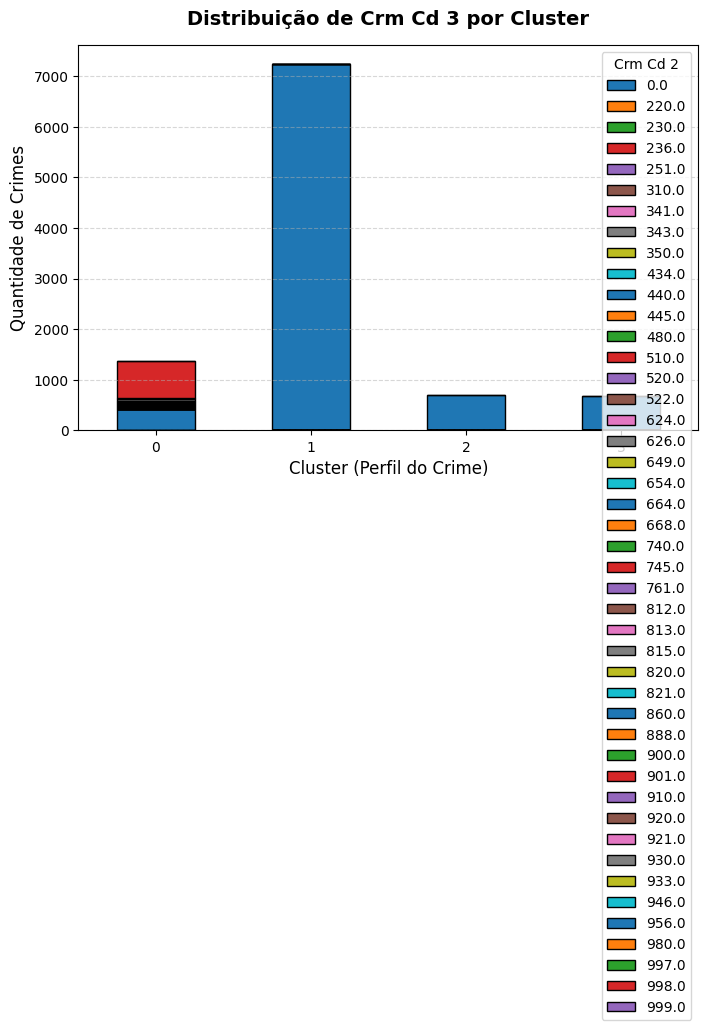

In [ ]:
cruzamento = pd.crosstab(df_cluster_crimes['cluster_perfil'], df_cluster_crimes["Crm Cd 2"])

ax = cruzamento.plot(kind='bar', stacked=True, figsize=(8, 5), edgecolor='black')

plt.title('Distribuição de Crm Cd 3 por Cluster', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cluster (Perfil do Crime)', fontsize=12)
plt.ylabel('Quantidade de Crimes', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title=cruzamento.columns.name, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

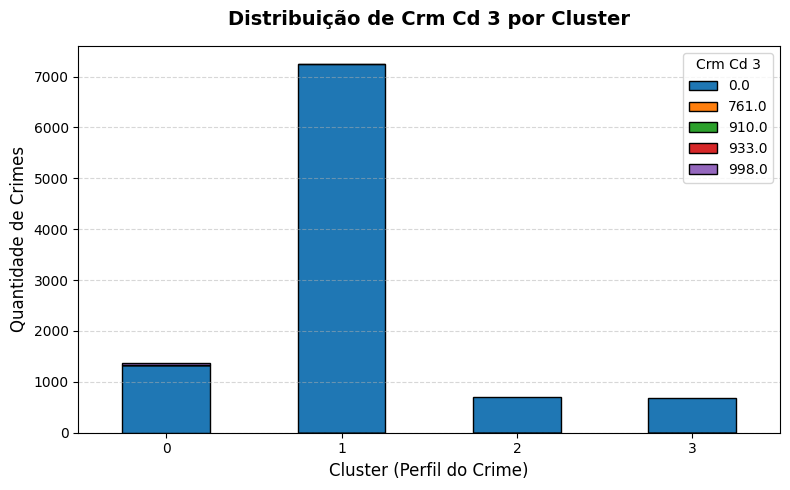

In [ ]:
cruzamento = pd.crosstab(df_cluster_crimes['cluster_perfil'], df_cluster_crimes["Crm Cd 3"])

ax = cruzamento.plot(kind='bar', stacked=True, figsize=(8, 5), edgecolor='black')

plt.title('Distribuição de Crm Cd 3 por Cluster', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cluster (Perfil do Crime)', fontsize=12)
plt.ylabel('Quantidade de Crimes', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title=cruzamento.columns.name, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()